# Отчёт по лабораторной работе №4

## Взаимодействие Spring и PostgreSQL

**Дисциплина:** Разработка кроссплатформенных приложений, семестр 2

**Выполнил:** студент группы 12002408

Блинов Кирилл Игоревич

**Проверил:** ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич

<br>
<br>

**Сайт курсового проекта:** [https://hki-stroitel.ru/](https://hki-stroitel.ru/)


<p align="justify"><strong>Цель работы:</strong> получить практические навыки взаимодействия Spring Boot и PostgreSQL, настроить хранение задач, связи между сущностями и историю изменений.</p>

<h2 align="center">Задание</h2>

1. Изучить теоретический материал.
2. Написать приложение, следуя примеру из методических указаний.
3. Выполнить дополнительное задание.
4. Сделать отчёт.

Дополнительное задание включает время создания, приоритет и категорию задачи, таблицу подзадач, связь задач с пользователями, историю входов и историю изменений задач.


## Ход работы

### 1. Основа приложения

За основу взято готовое приложение расписания из лабораторной №3. Сохранены расписание, студии, мероприятия, карта и журнал посещаемости. Пример списка задач из методички адаптирован к курсовому проекту: добавлен раздел «Подготовка мероприятий» с задачами и подзадачами для администратора и методиста.

Приложение использует Java 17, Spring Boot, Spring Data JPA, Hibernate и PostgreSQL. Интерфейс реализован на React. Серверная безопасность из предыдущей лабораторной сохранена.

Отчёт содержит текстовые ячейки с примерами Java-кода и встроенными скриншотами. Установка зависимостей и запуск приложения в Google Colab не выполняются.


### 2. Подключение PostgreSQL

В Gradle подключены `spring-boot-starter-data-jpa` и драйвер `org.postgresql:postgresql`. PostgreSQL 16 запускается сервисом `db` из `docker-compose.yml`.

| Параметр | Значение для локальной лабораторной |
| --- | --- |
| JDBC URL | `jdbc:postgresql://localhost:5544/raspisa_lab4` |
| Пользователь БД | `raspisa` |
| Учебный пароль БД | `Lab4!2026` |
| Драйвер | `org.postgresql.Driver`, определяется по JDBC URL |
| Настройка Hibernate | `spring.jpa.hibernate.ddl-auto=update` |
| Хранение данных Docker | Том `raspisa-lab4_lab4_pgdata` |

Внутри контейнера PostgreSQL слушает порт 5432; на этом ПК используется порт 5544. Hibernate создаёт таблицы и внешние ключи при запуске приложения. Для просмотра SQL в журнале можно задать `SHOW_SQL=true`.

Параметры подключения переопределяются переменными `DB_URL`, `DB_USERNAME` и `DB_PASSWORD`. В `application.yml` по умолчанию выбран PostgreSQL. Профиль `h2` оставлен только как отдельный запасной режим; результаты этой работы получены на PostgreSQL.


### 3. Структура данных

| Сущность | Таблица | Назначение и связи |
| --- | --- | --- |
| `User` | `users` | ID, логин, имя, email, хеш пароля и роль |
| `Task` | `tasks` | Название, описание, дата создания, приоритет, категория, статус, автор |
| `SubTask` | `sub_task` | Описание и статус подзадачи; `task_id` указывает на задачу |
| `LoginHistory` | `login_history` | Дата успешного входа, IP-адрес и `user_id` |
| `TaskHistory` | `task_history` | Дата изменения, действие, старое и новое состояние, задача и автор изменения |

Один пользователь может создать несколько задач. Одна задача может иметь несколько подзадач и записей истории. Один пользователь может иметь несколько записей о входах. Связи задаются аннотациями `@ManyToOne` и `@OneToMany` и поддерживаются внешними ключами в PostgreSQL.

Использована существующая таблица `users`, чтобы сохранить вход и роли из лабораторной №3. Email учебных пользователей имеет вид `methodist@raspisa.local`; пароль хранится как BCrypt-хеш и не возвращается в DTO.


### 4. Сущность задачи

Аннотация `@Entity` обозначает сущность JPA, `@Table` задаёт имя таблицы, `@Id` и `@GeneratedValue` описывают автоматически создаваемый идентификатор.

В задаче есть время создания `createdAt`, приоритет `LOW`, `NORMAL` или `HIGH`, категория и статус `TODO`, `IN_PROGRESS` или `DONE`. Автор определяется по текущему вошедшему пользователю на сервере. Передать другого автора через форму нельзя.


```java
package ru.raspisa.entity;

import jakarta.persistence.*;
import java.time.Instant;
import java.util.ArrayList;
import java.util.List;

@Entity
@Table(name = "tasks")
public class Task {
    public enum Status { TODO, IN_PROGRESS, DONE }
    public enum Priority { LOW, NORMAL, HIGH }

    @Id @GeneratedValue(strategy = GenerationType.IDENTITY)
    public Long id;
    @Column(nullable = false, length = 200)
    public String title;
    @Column(nullable = false, columnDefinition = "text")
    public String description = "";
    @Column(nullable = false, updatable = false)
    public Instant createdAt = Instant.now();
    @Enumerated(EnumType.STRING) @Column(nullable = false)
    public Priority priority = Priority.NORMAL;
    @Column(nullable = false, length = 100)
    public String category;
    @Enumerated(EnumType.STRING) @Column(nullable = false)
    public Status status = Status.TODO;
    @ManyToOne(fetch = FetchType.LAZY, optional = false)
    @JoinColumn(name = "user_id", nullable = false)
    public User owner;
    @Column(nullable = false)
    public boolean deleted;
    @OneToMany(mappedBy = "task", cascade = CascadeType.ALL, orphanRemoval = true)
    @OrderBy("id ASC")
    public List<SubTask> subtasks = new ArrayList<>();
}
```


### 5. Подзадачи

Каждая подзадача хранит ID, описание, признак выполнения и ссылку на родительскую задачу. Связь `Task.subtasks` реализует отношение «один ко многим».

В форме можно добавить подзадачу, отметить её выполненной и удалить. Сервер проверяет, что изменяемая подзадача относится к указанной задаче.


```java
package ru.raspisa.entity;

import jakarta.persistence.*;

@Entity
@Table(name = "sub_task")
public class SubTask {
    @Id @GeneratedValue(strategy = GenerationType.IDENTITY)
    public Long id;
    @Column(nullable = false, length = 500)
    public String description;
    @Column(nullable = false)
    public boolean completed;
    @ManyToOne(fetch = FetchType.LAZY, optional = false)
    @JoinColumn(name = "task_id", nullable = false)
    public Task task;
}
```


### 6. Репозиторий

`TaskRepository` наследует `JpaRepository<Task, Long>`. Spring Data JPA предоставляет сохранение, поиск и удаление без ручной реализации SQL. Метод `findByDeletedFalseOrderByCreatedAtDescIdDesc` возвращает только активные задачи, сначала новые.


```java
package ru.raspisa.repository;

import org.springframework.data.jpa.repository.JpaRepository;
import ru.raspisa.entity.Task;
import java.util.List;

public interface TaskRepository extends JpaRepository<Task, Long> {
    List<Task> findByDeletedFalseOrderByCreatedAtDescIdDesc();
}
```


### 7. Сервис и транзакции

Логика находится в `TaskService`, помеченном `@Transactional`. Сохранение задачи и запись истории выполняются в одной транзакции. Если операция завершается ошибкой, связанные изменения откатываются.

При создании сервер назначает автора, сохраняет задачу, получает ID и добавляет первую запись истории. Контроллер возвращает статус `201 Created`.


```java
public TaskView create(TaskRequest request) {
        var task = new Task();
        task.owner = currentUser();
        apply(task, request);
        tasks.saveAndFlush(task);
        record(task, "CREATE", null);
        return view(task);
    }
```


При изменении сначала сохраняется снимок предыдущего состояния, затем применяются новые значения и записывается история.


```java
public TaskView update(long id, TaskRequest request) {
        var task = find(id);
        String before = snapshot(task);
        apply(task, request);
        record(task, "UPDATE", before);
        return view(task);
    }
```


### 8. История изменений

`TaskHistory` содержит дату, действие, пользователя и снимки состояния до и после изменения. Записи создаются при добавлении, изменении и удалении задачи, а также при работе с подзадачами.

В интерфейсе кнопка «История изменений» открывает записи с колонками «До изменения» и «После изменения». При создании предыдущего состояния ещё нет. При удалении задача помечается `deleted=true` и скрывается из списка, а история сохраняется в базе.


```java
package ru.raspisa.entity;

import jakarta.persistence.*;
import java.time.Instant;

@Entity
@Table(name = "task_history")
public class TaskHistory {
    @Id @GeneratedValue(strategy = GenerationType.IDENTITY)
    public Long id;
    @Column(nullable = false)
    public Instant changedAt = Instant.now();
    @Column(nullable = false, length = 40)
    public String action;
    @Column(columnDefinition = "text")
    public String oldState;
    @Column(nullable = false, columnDefinition = "text")
    public String newState;
    @ManyToOne(fetch = FetchType.LAZY, optional = false)
    @JoinColumn(name = "task_id", nullable = false)
    public Task task;
    @ManyToOne(fetch = FetchType.LAZY, optional = false)
    @JoinColumn(name = "user_id", nullable = false)
    public User actor;
}
```


### 9. История входов

После успешной проверки логина и пароля `SecuritySessionService` вызывает `LoginHistoryService.record`. Сохраняются пользователь, время входа и IP-адрес соединения. Неверный пароль не создаёт запись об успешном входе.

История доступна только администратору через `/api/login-history`; интерфейс показывает последние 50 успешных входов. При локальной проверке адрес `0:0:0:0:0:0:0:1` означает IPv6 localhost.


```java
package ru.raspisa.entity;

import jakarta.persistence.*;
import java.time.Instant;

@Entity
@Table(name = "login_history")
public class LoginHistory {
    @Id @GeneratedValue(strategy = GenerationType.IDENTITY)
    public Long id;
    @Column(nullable = false)
    public Instant loggedAt = Instant.now();
    @Column(nullable = false, length = 64)
    public String ipAddress;
    @ManyToOne(fetch = FetchType.LAZY, optional = false)
    @JoinColumn(name = "user_id", nullable = false)
    public User user;
}
```


```java
public void record(String login, String ipAddress) {
        var entry = new LoginHistory();
        entry.user = users.findByLogin(login);
        entry.ipAddress = ipAddress == null ? "unknown" : ipAddress;
        history.save(entry);
    }
```


### 10. Контроллер и права доступа

`TaskController` получает запрос, проверяет входные данные через `@Valid` и передаёт работу сервису. Защита действует и в фильтре Spring Security, и через `@PreAuthorize` на контроллере.

| Роль | Возможности |
| --- | --- |
| `ADMIN` | Вся панель, задачи подготовки и история входов |
| `METHODIST` | Мероприятия и задачи их подготовки |
| `TEACHER` | Только журнал посещаемости |
| `STUDENT` | Просмотр мероприятий |

Для операций изменения требуется CSRF-токен. Без входа защищённые API отвечают `401`, при недостаточных правах – `403`.

| HTTP-метод | Адрес | Назначение |
| --- | --- | --- |
| GET | `/api/tasks` | Активные задачи |
| POST | `/api/tasks` | Создать задачу |
| PUT | `/api/tasks/{id}` | Изменить задачу |
| DELETE | `/api/tasks/{id}` | Убрать задачу из активного списка, сохранив историю |
| POST | `/api/tasks/{id}/subtasks` | Добавить подзадачу |
| PUT | `/api/tasks/{id}/subtasks/{subtaskId}` | Изменить описание или статус подзадачи |
| DELETE | `/api/tasks/{id}/subtasks/{subtaskId}` | Удалить подзадачу |
| GET | `/api/tasks/{id}/history` | История задачи |
| GET | `/api/login-history` | История входов для администратора |

Вместо `{id}` в запросе подставляется число без фигурных скобок, например `/api/tasks/1/history`.


```java
@RestController
@RequestMapping("/api/tasks")
@PreAuthorize("hasAnyRole('ADMIN', 'METHODIST')")
public class TaskController {
    private final TaskService tasks;

    public TaskController(TaskService tasks) { this.tasks = tasks; }

    @PostMapping
    public ResponseEntity<TaskView> create(@Valid @RequestBody TaskRequest request) {
        return ResponseEntity.status(HttpStatus.CREATED).body(tasks.create(request));
    }
}
```


### 11. Запуск на этом ПК

1. Открыть Docker Desktop и дождаться запуска движка.
2. Запустить `start-lab4.bat` в папке лабораторной. Скрипт поднимет PostgreSQL и запустит готовый JAR. Если JAR отсутствует, сначала выполнится сборка Gradle.
3. Открыть страницу входа приложения.
4. Войти под нужной учётной записью.

| Логин | Учебный пароль |
| --- | --- |
| `admin` | `Admin!2026` |
| `teacher` | `Teacher!2026` |
| `student` | `Student!2026` |
| `methodist` | `Methodist!2026` |

Для готового JAR требуется Java 17. Для повторной сборки интерфейса также нужен Node.js. Из терминала после запуска PostgreSQL приложение можно запустить командой `.\gradlew.bat bootRun`.

В pgAdmin подключение создаётся с хостом `localhost`, портом `5544`, базой `raspisa_lab4`, пользователем `raspisa` и указанным учебным паролем БД. Дополнительные команды и SQL-запросы находятся в файлах `ЗАПУСК.txt` и `sql/проверка.sql`.

Данные сохраняются в Docker volume. Обычная остановка контейнера их не удаляет.


### 12. Проверка выполнения

Проверка проведена на PostgreSQL 16.15. Через интерфейс создана задача «Подготовить мастер-класс по фотографии», добавлены две подзадачи, первая отмечена выполненной, статус задачи изменён на «В работе».

SQL-запрос к PostgreSQL подтвердил следующие данные демонстрационной записи:

| Поле | Сохранённое значение |
| --- | --- |
| `tasks.id` | `1` |
| Название | Подготовить мастер-класс по фотографии |
| Приоритет | `HIGH` |
| Категория | Мастер-класс |
| Статус | `IN_PROGRESS` |
| Автор | `methodist` |
| Подзадачи | 2, из них выполнена 1 |
| Записи истории задачи №1 | 5 |

После перезапуска приложения и контейнера PostgreSQL задача, обе подзадачи и выполненная отметка сохранились. Дополнительно проверены создание, чтение, изменение и удаление временной задачи через API на PostgreSQL, сохранность истории и запреты для студента и преподавателя.

Автоматические тесты проекта: 51 выполнен успешно. В тестах используется отдельная база в памяти; результаты ручной проверки и скриншоты относятся к PostgreSQL. Код проверок не вставлен в блокнот.


### 13. Скриншоты приложения

Снимки сделаны при работе локальной лабораторной, подключённой к PostgreSQL.


**Вход в приложение**

Форма входа использует пользователей из таблицы users.

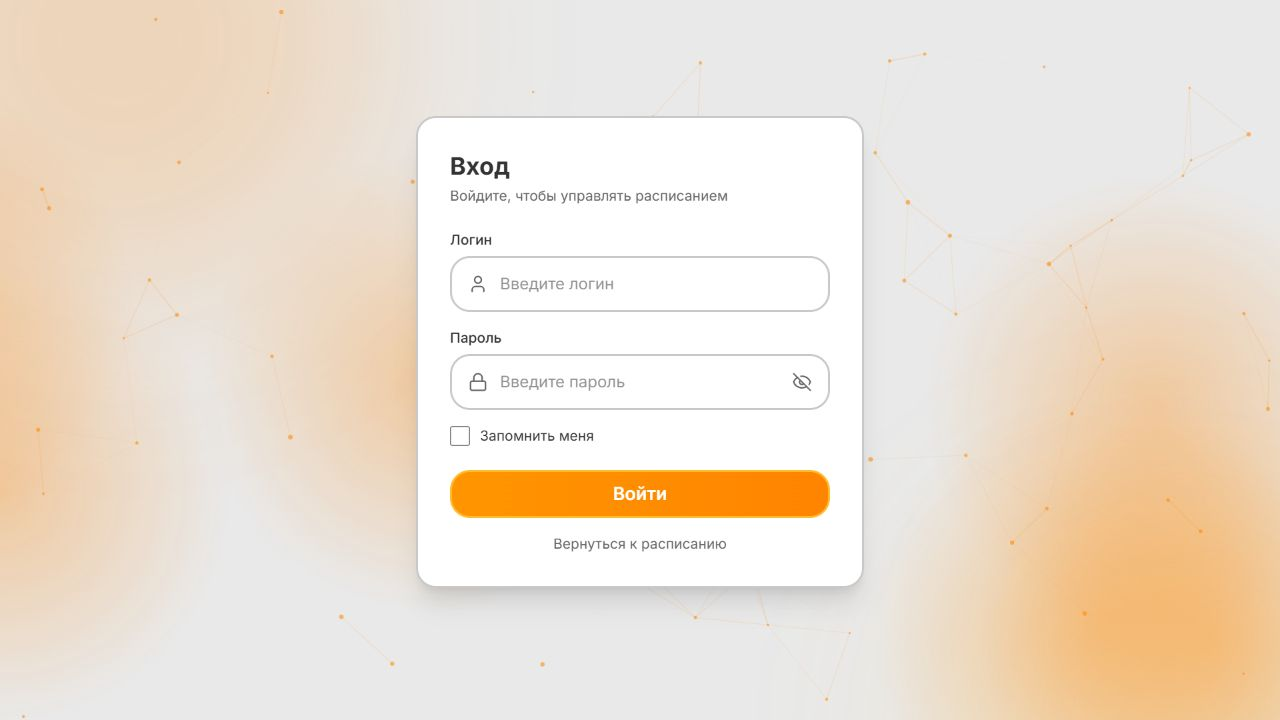

*Рисунок 1 – Вход в приложение*


**Задача подготовки мероприятия**

В форме видны приоритет, категория, статус и две подзадачи. Первая подзадача выполнена.

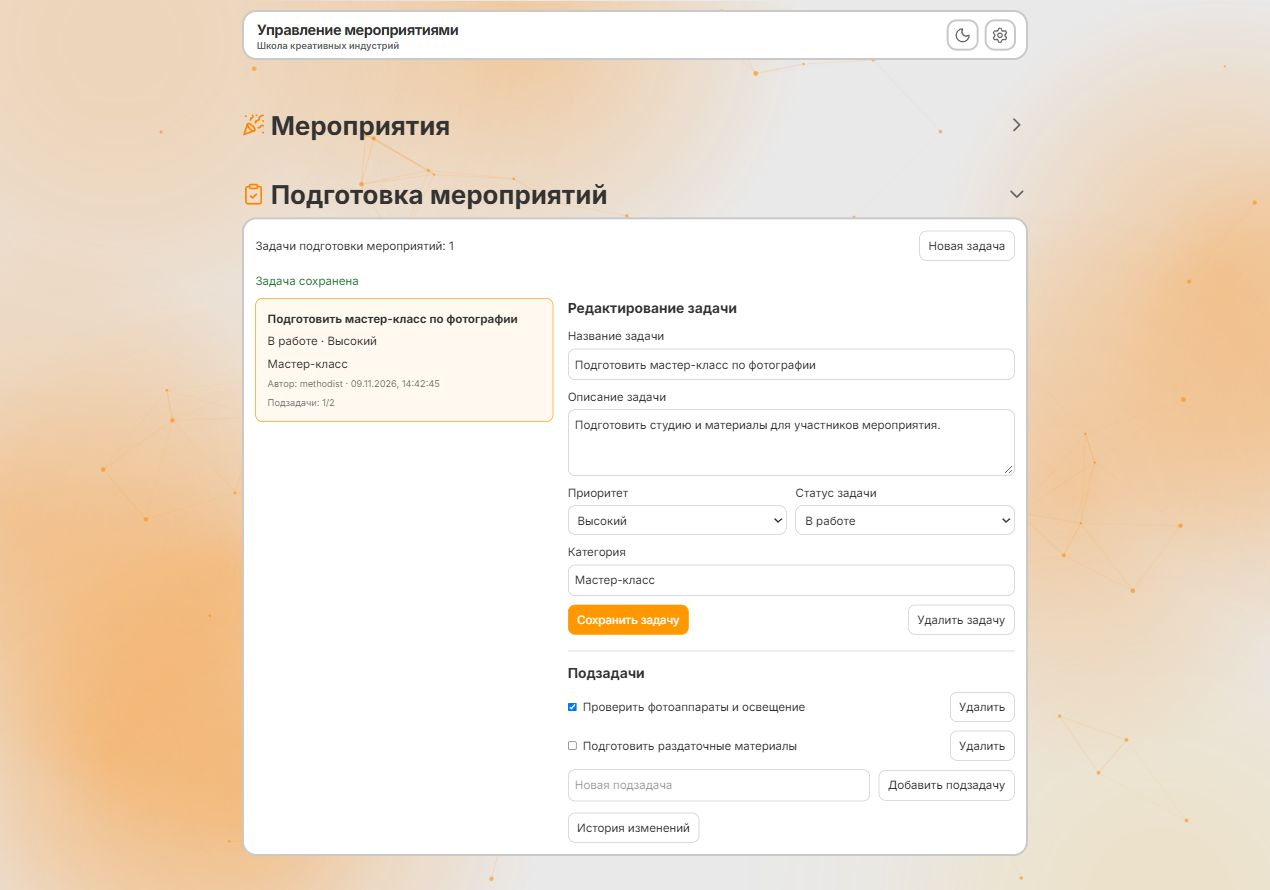

*Рисунок 2 – Задача подготовки мероприятия*


**История изменений задачи**

Развёрнута запись изменения статуса: до изменения TODO, после изменения IN_PROGRESS.

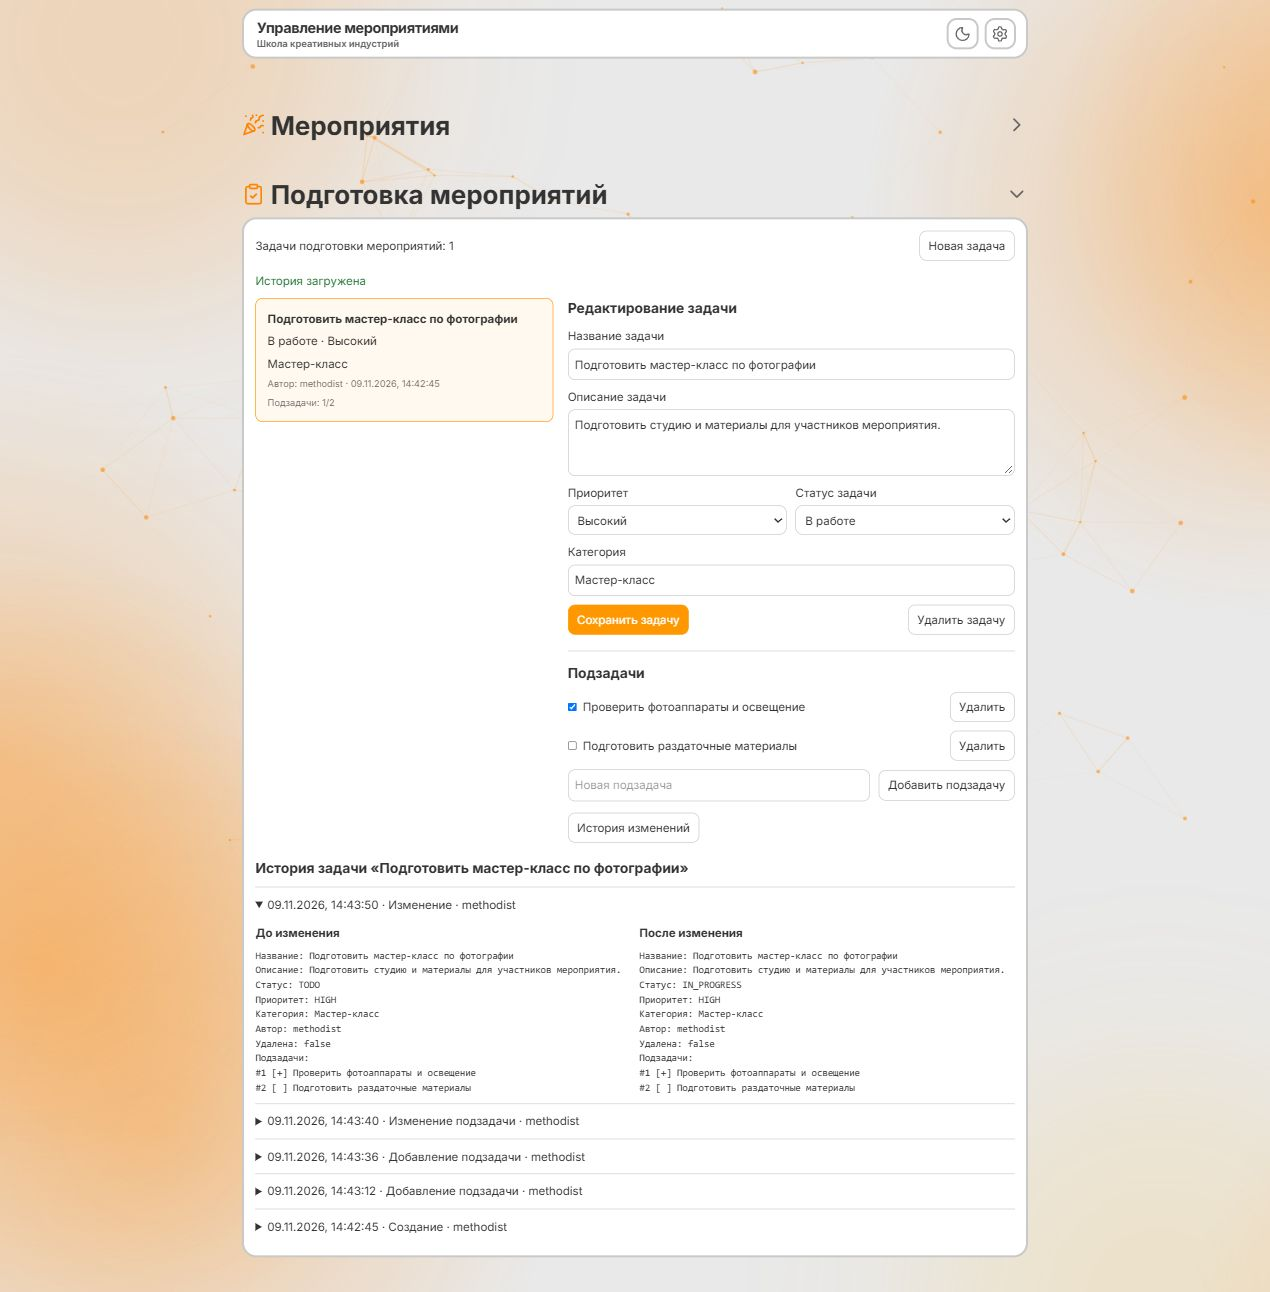

*Рисунок 3 – История изменений задачи*


**История успешных входов**

Администратор видит дату, логин и IP-адрес пользователя.

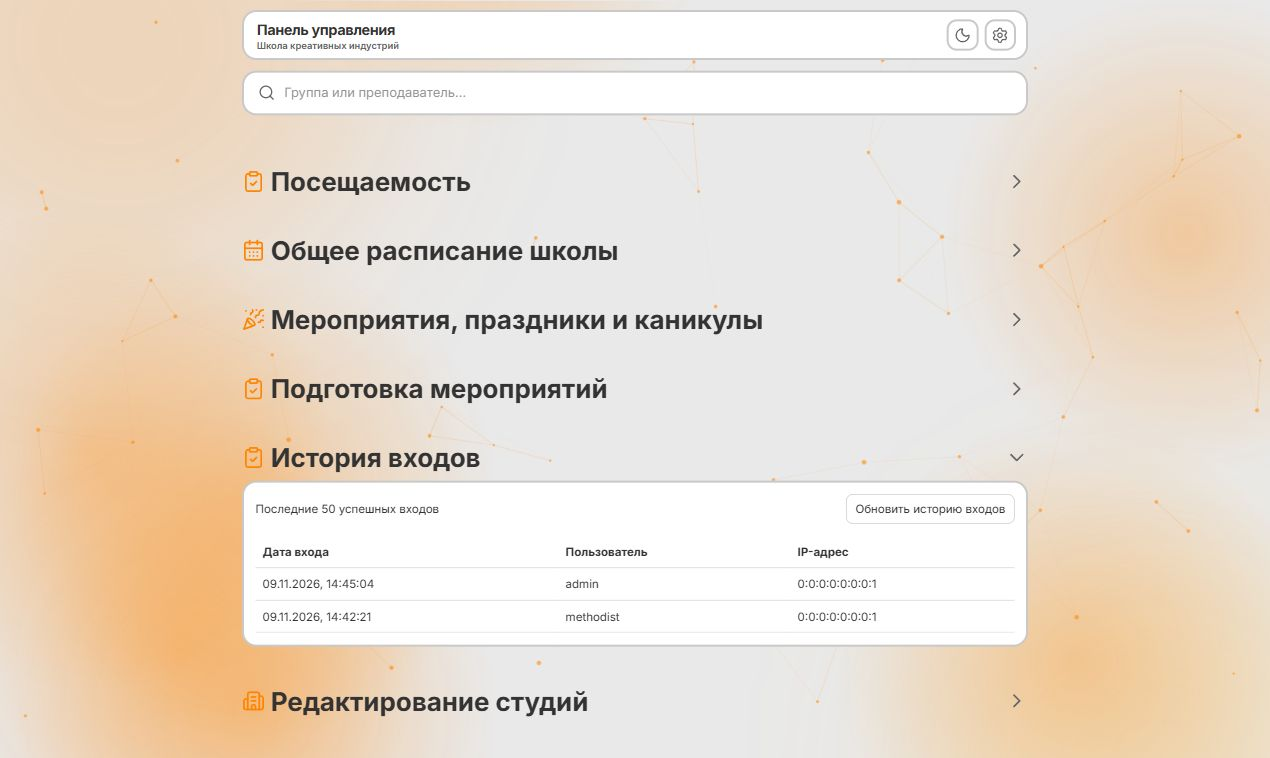

*Рисунок 4 – История успешных входов*


**Данные после перезапуска**

После перезапуска приложения и PostgreSQL повторно открыт сохранённый пример с двумя подзадачами.

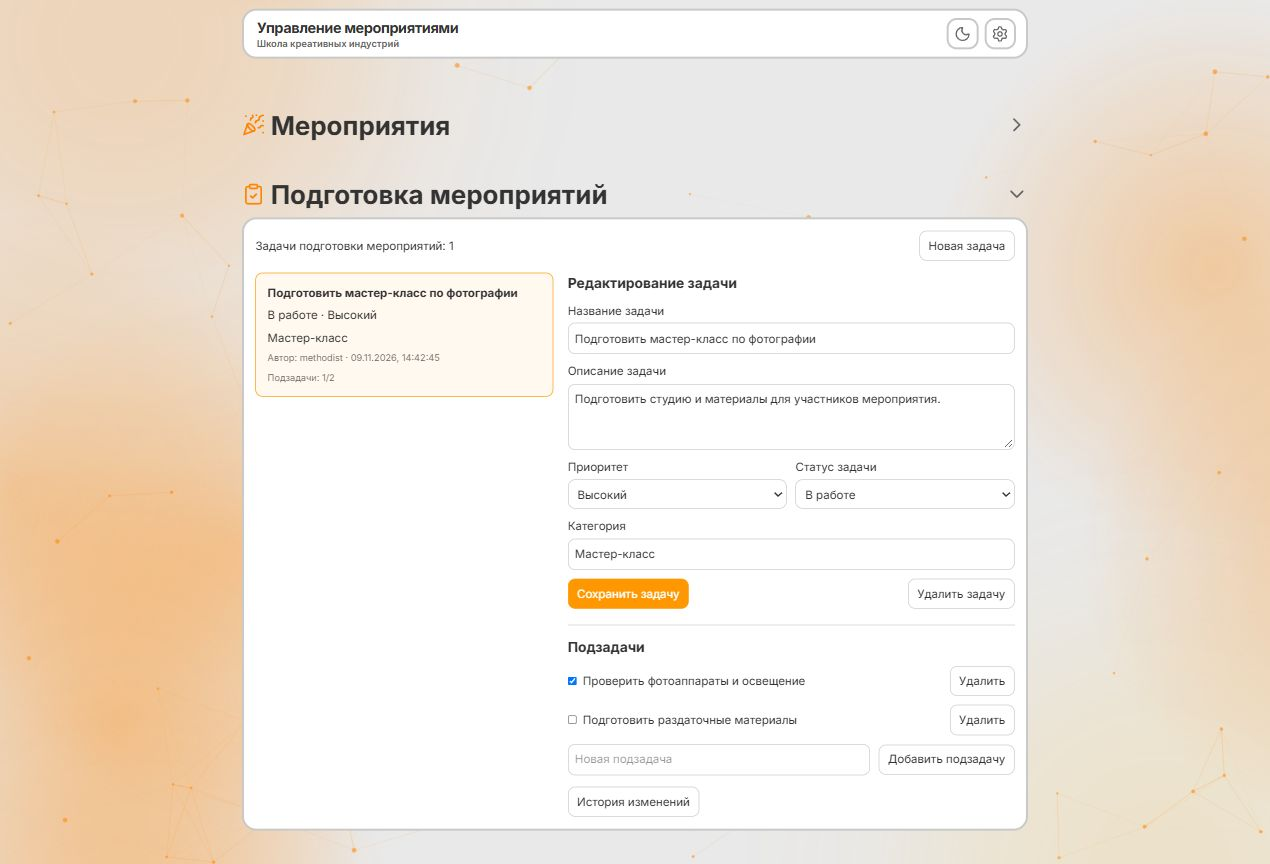

*Рисунок 5 – Данные после перезапуска*


## Вывод

Изучил взаимодействие Spring Boot и PostgreSQL, реализовав хранение задач, подзадач, пользователей и истории операций.
